# Table of Contents
- [3.2 Recap and the road ahead](#recap)
- [3.3 Method 3: Linear Interpolation (False Position)](#false-position)
- [3.4 Method 4: Newton-Raphson](#newton)
- [3.5 Method 5: The Secant Method](#secant)
- [3.6 How fast is fast? Order of convergence](#convergence)
- [3.7 When things go wrong](#failure)
- [3.8 Using the professionals: `scipy.optimize`](#scipy)
- [3.9 Finding *all* the roots in an interval](#all-roots)
- [Problems](#problems)

# 3.2 Recap and the road ahead <a class="anchor" id="recap"></a>
In the previous notebook we met two ways of solving $f(x)=0$:

1. **Rearrangement** $x_{n+1}=\varrho(x_n)$ - simple, but only works if $\varrho$ is slowly-varying near the root (more precisely, $|\varrho'(\xi)|<1$).
2. **Interval bisection (binary chop)** - bullet-proof once you have bracketed a sign change, but slow: every iteration only halves the interval, so you gain roughly one binary digit (about 0.3 decimal digits) per step.

In this notebook we finish the root-finding toolkit. We will keep using the same test equation

$$f(x)\equiv 3x^5 - x - 4 = 0,$$

whose real root is $\xi \approx 1.1125$, so that every method can be compared on an equal footing.

In [1]:
# BLOCK 3.2.1
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return 3*x**5 - x - 4

def df(x):
    """The analytic derivative of f - Newton-Raphson will need this."""
    return 15*x**4 - 1

# A reference value obtained by running bisection to machine precision.
def bisection(func, a, b, tol=1e-15, max_iter=200):
    fa = func(a)
    for _ in range(max_iter):
        c = 0.5*(a + b)
        fc = func(c)
        if np.sign(fc) == np.sign(fa):
            a, fa = c, fc
        else:
            b = c
        if abs(b - a) < tol:
            break
    return 0.5*(a + b)

XI = bisection(f, 1, 2)
print(f'reference root xi = {XI:.15f}')

reference root xi = 1.112506410533339


# 3.3 Method 3: Linear Interpolation (False Position / *Regula Falsi*) <a class="anchor" id="false-position"></a>
Bisection throws away a lot of information. It only cares about the *sign* of $f(a)$ and $f(b)$, not their *size*. If $|f(a)|$ is tiny and $|f(b)|$ is huge, common sense says the root is much closer to $a$.

Linear interpolation uses this information. Draw a straight line (a chord) between $(a, f(a))$ and $(b, f(b))$ and find where it crosses the $x$-axis:

$$c = b - f(b)\,\frac{b-a}{f(b)-f(a)} = \frac{a f(b) - b f(a)}{f(b)-f(a)}.$$

We then keep whichever sub-interval, $[a,c]$ or $[c,b]$, still contains the sign change - exactly as in bisection. The root therefore always stays bracketed (so the method can't run away), but we are usually much closer after each step.

In [2]:
# BLOCK 3.3.1
def false_position(func, a, b, tol=1e-12, max_iter=100):
    """Return (root, history) using the method of false position."""
    fa, fb = func(a), func(b)
    if np.sign(fa) == np.sign(fb):
        raise ValueError(f'No sign change between {a} and {b}')
    history = []
    c_old = a
    for _ in range(max_iter):
        c = (a*fb - b*fa) / (fb - fa)      # where the chord crosses y = 0
        fc = func(c)
        history.append(c)
        if abs(c - c_old) < tol or fc == 0:
            break
        if np.sign(fc) == np.sign(fa):
            a, fa = c, fc
        else:
            b, fb = c, fc
        c_old = c
    return c, history

root, hist = false_position(f, 1, 2)
print(f'root = {root:.15f} after {len(hist)} iterations')

root = 1.112506410530123 after 100 iterations


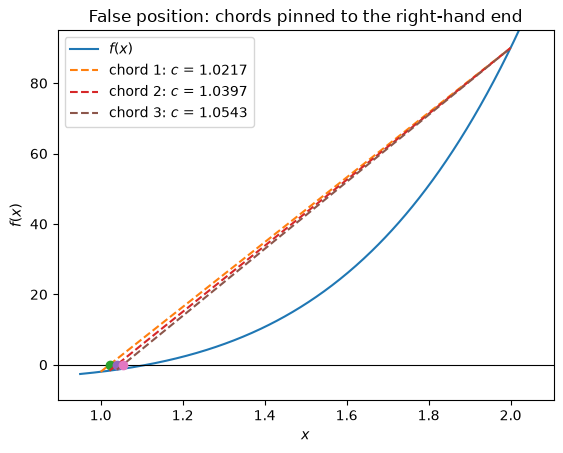

In [3]:
# BLOCK 3.3.2
# Picture the first few chords
x = np.linspace(0.95, 2.05, 400)
plt.plot(x, f(x), label='$f(x)$')
plt.axhline(0, color='black', lw=0.8)
a, b = 1, 2
for k in range(3):
    c = (a*f(b) - b*f(a)) / (f(b) - f(a))
    plt.plot([a, b], [f(a), f(b)], '--', label=f'chord {k+1}: $c$ = {c:.4f}')
    plt.plot(c, 0, 'o')
    if np.sign(f(c)) == np.sign(f(a)):
        a = c
    else:
        b = c
plt.xlabel('$x$'); plt.ylabel('$f(x)$'); plt.legend(); plt.ylim(-10, 95)
plt.title('False position: chords pinned to the right-hand end')
plt.show()

Notice something irritating: because $f$ is convex here, the right-hand end point $b=2$ **never moves**. Every chord pivots about $(2, f(2))$, so false position creeps up on the root from one side only. It still converges, but painfully slowly - look back at BLOCK 3.3.1: it used all 100 iterations and *still* had not met the $10^{-12}$ tolerance. (A fix known as the *Illinois algorithm* halves the stored value of the stagnant endpoint - try it in the exercises.)

# 3.4 Method 4: Newton-Raphson <a class="anchor" id="newton"></a>
Newton-Raphson is the work-horse of root finding and probably the single most important algorithm in this chapter. Instead of a chord we use the **tangent**.

Expand $f$ in a Taylor series about our current guess $x_n$:

$$f(x) = f(x_n) + (x - x_n) f'(x_n) + \tfrac{1}{2}(x-x_n)^2 f''(x_n) + \dots$$

Throw away everything beyond the linear term, set $f(x)=0$ and solve for $x$. Calling that solution $x_{n+1}$:

$$\boxed{x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}}$$

Geometrically: follow the tangent at $x_n$ down to the axis.

Notice this is just a rearrangement formula $x_{n+1}=\varrho(x_n)$ with the cleverly chosen $\varrho(x) = x - f(x)/f'(x)$. At the root $\varrho'(\xi) = f(\xi)f''(\xi)/f'(\xi)^2 = 0$, which is as "slowly-varying" as it's possible to be - and that is the secret of its speed.

In [4]:
# BLOCK 3.4.1
def newton_raphson(func, dfunc, x0, tol=1e-12, max_iter=50):
    """Return (root, history) using Newton-Raphson."""
    x = x0
    history = [x]
    for _ in range(max_iter):
        step = func(x) / dfunc(x)
        x = x - step
        history.append(x)
        if abs(step) < tol:
            break
    return x, history

root, hist = newton_raphson(f, df, x0=2.0)
for n, xn in enumerate(hist):
    print(f'n = {n}:  x_n = {xn:.15f}   error = {abs(xn - XI):.2e}')

n = 0:  x_n = 2.000000000000000   error = 8.87e-01
n = 1:  x_n = 1.623430962343096   error = 5.11e-01
n = 2:  x_n = 1.350094109624298   error = 2.38e-01
n = 3:  x_n = 1.184097413492344   error = 7.16e-02
n = 4:  x_n = 1.120941542699779   error = 8.44e-03
n = 5:  x_n = 1.112637963172249   error = 1.32e-04
n = 6:  x_n = 1.112506443052483   error = 3.25e-08
n = 7:  x_n = 1.112506410533341   error = 2.00e-15
n = 8:  x_n = 1.112506410533339   error = 0.00e+00


Look at the error column. Once we are close, the number of correct digits roughly **doubles** every iteration ($10^{-3}\to10^{-6}\to10^{-12}$). This is called **quadratic convergence**, and we will make it precise in section 3.6.

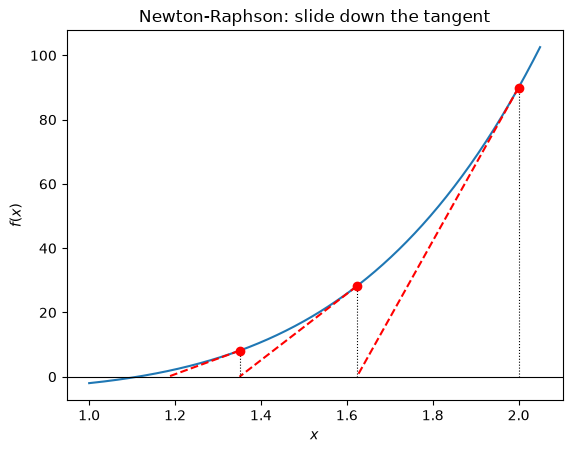

In [5]:
# BLOCK 3.4.2
# Visualise the tangents
x = np.linspace(1.0, 2.05, 400)
plt.plot(x, f(x), label='$f(x)$')
plt.axhline(0, color='black', lw=0.8)
for xn, xn1 in zip(hist[:3], hist[1:4]):
    plt.plot([xn, xn1], [f(xn), 0], 'r--')          # tangent line
    plt.plot([xn, xn], [0, f(xn)], 'k:', lw=0.8)     # drop back up to the curve
    plt.plot(xn, f(xn), 'ro')
plt.xlabel('$x$'); plt.ylabel('$f(x)$')
plt.title('Newton-Raphson: slide down the tangent')
plt.show()

# 3.5 Method 5: The Secant Method <a class="anchor" id="secant"></a>
Newton-Raphson needs $f'(x)$. Sometimes the derivative is horrible to write down, or $f$ is only available as the output of another program (e.g. an ODE solver - see the shooting method in Chapter 5). The secant method replaces the derivative with the gradient of the line through the last two points:

$$f'(x_n) \approx \frac{f(x_n) - f(x_{n-1})}{x_n - x_{n-1}}
\quad\Longrightarrow\quad
x_{n+1} = x_n - f(x_n)\,\frac{x_n - x_{n-1}}{f(x_n) - f(x_{n-1})}.$$

This looks just like false position! The difference is that we *don't* insist on keeping the root bracketed - we always use the two most recent points. We lose the safety guarantee but gain speed.

In [6]:
# BLOCK 3.5.1
def secant(func, x0, x1, tol=1e-12, max_iter=50):
    """Return (root, history) using the secant method."""
    history = [x0, x1]
    f0, f1 = func(x0), func(x1)
    for _ in range(max_iter):
        x2 = x1 - f1*(x1 - x0)/(f1 - f0)
        history.append(x2)
        if abs(x2 - x1) < tol:
            break
        x0, f0 = x1, f1
        x1, f1 = x2, func(x2)
    return x2, history

root, hist = secant(f, 1.0, 2.0)
for n, xn in enumerate(hist):
    print(f'n = {n}:  x_n = {xn:.15f}   error = {abs(xn - XI):.2e}')

n = 0:  x_n = 1.000000000000000   error = 1.13e-01
n = 1:  x_n = 2.000000000000000   error = 8.87e-01
n = 2:  x_n = 1.021739130434783   error = 9.08e-02
n = 3:  x_n = 1.039677557838628   error = 7.28e-02
n = 4:  x_n = 1.127262359182445   error = 1.48e-02
n = 5:  x_n = 1.110370832215220   error = 2.14e-03
n = 6:  x_n = 1.112447911626003   error = 5.85e-05
n = 7:  x_n = 1.112506645848533   error = 2.35e-07
n = 8:  x_n = 1.112506410507464   error = 2.59e-11
n = 9:  x_n = 1.112506410533339   error = 0.00e+00
n = 10:  x_n = 1.112506410533339   error = 0.00e+00


# 3.6 How fast is fast? Order of convergence <a class="anchor" id="convergence"></a>
Let $\epsilon_n = x_n - \xi$ be the error at step $n$. A method has **order of convergence** $p$ if, close to the root,

$$|\epsilon_{n+1}| \approx C\,|\epsilon_n|^p .$$

| Method | Order $p$ | Needs bracket? | Needs $f'$? |
| :--- | :---: | :---: | :---: |
| Rearrangement | 1 (linear) | no | no |
| Bisection | 1 (linear, $C=\tfrac12$) | yes | no |
| False position | 1 (usually) | yes | no |
| Secant | $\phi = \tfrac{1+\sqrt5}{2}\approx 1.618$ | no | no |
| Newton-Raphson | 2 (quadratic) | no | yes |

(Yes, that *is* the golden ratio turning up in the secant method!)

The cleanest way to *see* $p$ is to plot $\log|\epsilon_{n+1}|$ against $\log|\epsilon_n|$: the gradient of the line is $p$.

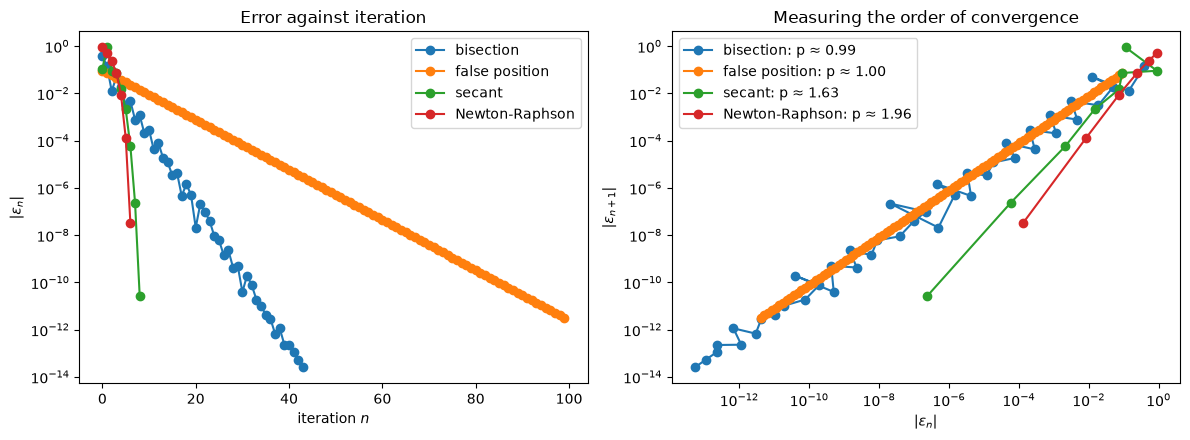

In [7]:
# BLOCK 3.6.1
def errors(history):
    e = np.abs(np.array(history) - XI)
    return e[e > 1e-14]          # discard values swamped by round-off

def bisection_history(func, a, b, n):
    hist = []
    for _ in range(n):
        c = 0.5*(a + b)
        hist.append(c)
        if np.sign(func(c)) == np.sign(func(a)):
            a = c
        else:
            b = c
    return hist

methods = {
    'bisection':      bisection_history(f, 1, 2, 45),
    'false position': false_position(f, 1, 2)[1],
    'secant':         secant(f, 1.0, 2.0)[1],
    'Newton-Raphson': newton_raphson(f, df, 2.0)[1],
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for name, hist in methods.items():
    e = errors(hist)
    ax1.semilogy(e, 'o-', label=name)
    if len(e) > 2:
        # fast methods: fit only the last few (asymptotic) points;
        # bisection's error is jumpy, so fit a line through all of them
        k = 4 if name in ('secant', 'Newton-Raphson') else len(e)
        p = np.polyfit(np.log(e[:-1][-k:]), np.log(e[1:][-k:]), 1)[0]
        ax2.loglog(e[:-1], e[1:], 'o-', label=f'{name}: p ≈ {p:.2f}')
ax1.set_xlabel('iteration $n$'); ax1.set_ylabel(r'$|\epsilon_n|$'); ax1.legend()
ax2.set_xlabel(r'$|\epsilon_n|$'); ax2.set_ylabel(r'$|\epsilon_{n+1}|$'); ax2.legend()
ax1.set_title('Error against iteration'); ax2.set_title('Measuring the order of convergence')
plt.tight_layout(); plt.show()

The measured slopes should be close to $1$, $1$, $1.6$ and $2$. Newton-Raphson reaches machine precision in a handful of steps, while bisection needs ~50.

# 3.7 When things go wrong <a class="anchor" id="failure"></a>
Speed has a price. Newton-Raphson is only guaranteed to converge if you start "close enough" to the root. Some classic failures:

1. **A stationary point**: if $f'(x_n)\approx 0$ the tangent is nearly flat and $x_{n+1}$ is flung far away.
2. **Cycles**: for $f(x)=x^3-2x+2$ starting at $x_0=0$ the iterates bounce $0\to1\to0\to1\dots$ forever.
3. **Repeated roots**: at a double root $f'(\xi)=0$ too, and convergence drops to linear.

Let's watch the cycle happen.

In [8]:
# BLOCK 3.7.1
g = lambda x: x**3 - 2*x + 2
dg = lambda x: 3*x**2 - 2
_, hist = newton_raphson(g, dg, 0.0, max_iter=8)
print('Starting at x0 = 0:  ', np.round(hist, 6))
_, hist = newton_raphson(g, dg, -2.0, max_iter=8)
print('Starting at x0 = -2: ', np.round(hist, 6))

Starting at x0 = 0:   [0. 1. 0. 1. 0. 1. 0. 1. 0.]
Starting at x0 = -2:  [-2.       -1.8      -1.769948 -1.769293 -1.769292 -1.769292]


**The moral:** in practice we combine methods. Use a safe bracketing method to get close, then switch to a fast open method to finish. This is exactly what professional root-finders do.

# 3.8 Using the professionals: `scipy.optimize` <a class="anchor" id="scipy"></a>
`scipy.optimize.brentq` implements **Brent's method**, which mixes bisection, secant and *inverse quadratic interpolation*. It needs a bracket and is guaranteed to converge, but is usually nearly as fast as the secant method. `scipy.optimize.newton` gives Newton-Raphson (or secant if you don't pass `fprime`). For most real work, `brentq` is the right default.

In [9]:
# BLOCK 3.8.1
from scipy import optimize

r1, info = optimize.brentq(f, 1, 2, full_output=True)
print(f'brentq : {r1:.15f}  ({info.iterations} iterations, {info.function_calls} calls)')
r2 = optimize.newton(f, 2.0, fprime=df)
print(f'newton : {r2:.15f}')
r3 = optimize.newton(f, 2.0)          # no derivative -> secant method
print(f'secant : {r3:.15f}')

brentq : 1.112506410533339  (9 iterations, 10 calls)
newton : 1.112506410533339
secant : 1.112506410533339


# 3.9 Finding *all* the roots in an interval <a class="anchor" id="all-roots"></a>
The unfinished `interval_bisection` idea from the previous notebook can now be completed properly. The strategy is:

1. Sample $f$ on a grid and look for every place where neighbouring values change sign (this is vectorised with numpy - no loop needed).
2. Hand each little bracket to `brentq`.

Grid spacing matters: if two roots are closer together than one grid step the sign may change twice and we'd miss them both. Always plot your function first!

roots: [-2.807735 -2.356058 -0.950781  0.        0.950781  2.356058  2.807735]


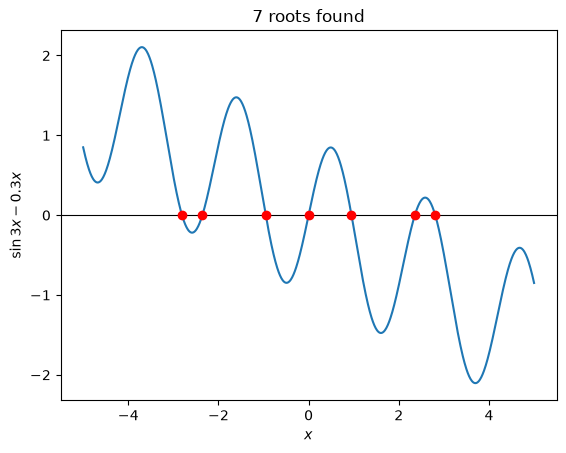

In [10]:
# BLOCK 3.9.1
def find_all_roots(func, a, b, n=1000):
    x = np.linspace(a, b, n)
    y = func(x)
    idx = np.where(np.sign(y[:-1]) * np.sign(y[1:]) < 0)[0]   # indices of sign changes
    return np.array([optimize.brentq(func, x[i], x[i+1]) for i in idx])

h = lambda x: np.sin(3*x) - 0.3*x
roots = find_all_roots(h, -5, 5)
print('roots:', np.round(roots, 6))

x = np.linspace(-5, 5, 1000)
plt.plot(x, h(x)); plt.axhline(0, color='k', lw=0.8)
plt.plot(roots, np.zeros_like(roots), 'ro')
plt.xlabel('$x$'); plt.ylabel(r'$\sin 3x - 0.3x$'); plt.title(f'{len(roots)} roots found')
plt.show()

# Problems <a class="anchor" id="problems"></a>

### Exercise 1 - The Illinois algorithm
Modify `false_position` so that whenever the same endpoint is retained twice in a row, its stored function value is halved (`fb = fb/2`). Show on a convergence plot that this restores super-linear convergence.

### Exercise 2 - Square roots like the Babylonians
Apply Newton-Raphson to $f(x)=x^2-a$. Show that the iteration becomes $x_{n+1}=\tfrac12\left(x_n + a/x_n\right)$. How many iterations from $x_0=1$ are needed for $\sqrt{2}$ to 15 digits?

### Exercise 3 - Basins of attraction
Newton-Raphson works for complex numbers too. Apply it to $z^3-1=0$ on a $500\times500$ grid of starting points $z_0$ in the square $|\text{Re}\,z|,|\text{Im}\,z|<1.5$ and colour each point by which of the three cube roots of unity it converges to. Plot with `plt.imshow`. (You have just drawn a *Newton fractal*!)

### Exercise 4 - A double root
Use Newton-Raphson on $f(x)=(x-1)^2(x+2)$ starting at $x_0=2$ and measure the order of convergence. Then use the modified iteration $x_{n+1}=x_n - 2f(x_n)/f'(x_n)$ and measure it again.

In [11]:
# Start working here